# Notebook 05 — Nivel II: análisis estadístico de tolerancias (Monte Carlo)
**TP Integrador — Filtros analógicos activos · Grupo 3 · LP Chebyshev I, orden 3 (RC + seguidor y Sallen–Key $k=1$, TL072CP)**

Consigna (Nivel II): (a) definir las distribuciones de los componentes; (b) ejecutar al menos 100 corridas **efectivamente distintas** en LTspice,
documentando cómo se generan las muestras; (c) obtener la distribución de los parámetros relevantes y el porcentaje de cumplimiento; (d) comparar con
la sensibilidad lineal; (e) repetir con tolerancias menores.

Contenido:
1. Distribuciones y escenarios.
2. Netlists de Monte Carlo para LTspice (`mc()` + `.step`), con sondas que registran el generador de números aleatorios, y verificación del netlist
   con el solver nodal del notebook 03.
3. Referencia independiente en Python: el mismo experimento sobre la transferencia exacta del circuito (100 000 muestras por escenario).
4. Predicción por sensibilidad lineal: desviaciones estándar de primer orden y un Monte Carlo *linealizado*.
5. Resultados de LTspice: lectura de `.log` y `.raw`, verificación de que las corridas son distintas, distribuciones, rendimiento y contraste.
6. Exportación para el informe.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import scipy
from scipy import optimize, stats
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, RES, LTS, MED = ROOT / 'figuras', ROOT / 'resultados', ROOT / 'ltspice', ROOT / 'mediciones'
for d_ in (FIG, RES, LTS, LTS / 'resultados'):
    d_.mkdir(exist_ok=True)

AZUL, NARANJA, VERDE, AMARILLO, MAGENTA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6, 'axes.edgecolor': '#6b6b67',
    'axes.linewidth': 0.8, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight'); fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')

def num(x, nd=3):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x
    t = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + t) if x < 0 else t

DATOS = json.load(open(RES / 'componentes.json', encoding='utf-8'))
COMP, PL, SERIE = DATOS['componentes'], DATOS['plantilla'], DATOS['resistencias_en_serie']
AP, AS, FP, FS = PL['Ap'], PL['As'], PL['fp'], PL['fs']
print('Plantilla:', PL)

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | Matplotlib 3.11.2 | pandas 3.0.5
Plantilla: {'Ap': 1.0, 'As': 24.0, 'fp': 1000.0, 'fs': 4000.0}


## 1. Distribuciones y escenarios
**(a) Distribuciones.** Cada componente se modela como una variable aleatoria **uniforme e independiente** en $[x_0(1-t),\,x_0(1+t)]$, con $x_0$ el
valor nominal y $t$ la tolerancia. Es la hipótesis más conservadora compatible con la información disponible (solo se conoce el intervalo de
tolerancia del fabricante). Las resistencias que se arman como dos en serie se sortean **por separado** (cada una con su tolerancia), igual que en
el circuito real; la resistencia del generador, $R_s = 50\ \Omega$, es fija. En total varían **nueve** elementos por corrida.

**Escenarios.** E1 es el ejemplo de la guía ($R \pm 5\,\%$, $C \pm 10\,\%$); E2 corresponde a los componentes realmente usados en el prototipo
(resistencias de $\pm 1\,\%$ y capacitores código K, $\pm 10\,\%$); E3 y E4 repiten el análisis con tolerancias menores (punto e).

**Criterio de cumplimiento** (siempre contra la plantilla, no contra la función de diseño): atenuación máxima en la banda de paso
$A_{p,\max} = \max_{f\le f_p} G - \min_{f\le f_p} G \le 1$ dB y atenuación a 4 kHz $A(f_s) = \max_{f\le f_p} G - G(f_s) \ge 24$ dB, con
$G = 20\log_{10}|V_6/V_{in}|$.

In [2]:
ESC = pd.DataFrame([
    ('E1', 0.05, 0.10, 'ejemplo de la guía'),
    ('E2', 0.01, 0.10, 'componentes del prototipo (R 1 %, C código K)'),
    ('E3', 0.01, 0.05, 'tolerancias menores (C código J)'),
    ('E4', 0.01, 0.02, 'tolerancias menores (C de precisión)'),
], columns=['escenario', 'tolR', 'tolC', 'motivo']).set_index('escenario')
N_RUN = 500   # corridas por escenario en LTspice (la guía pide al menos 100)

ELEM = ['R0a', 'R0b', 'R1a', 'R1b', 'R2a', 'R2b', 'C0', 'C1', 'C2']
NOM = {'R0a': SERIE['R0'][0], 'R0b': SERIE['R0'][1], 'R1a': SERIE['R1'][0], 'R1b': SERIE['R1'][1],
       'R2a': SERIE['R2'][0], 'R2b': SERIE['R2'][1], 'C0': COMP['C0'], 'C1': COMP['C1'], 'C2': COMP['C2']}
RS = COMP['Rs']
def tol_de(e, esc):
    return ESC.loc[esc, 'tolR'] if e.startswith('R') else ESC.loc[esc, 'tolC']
print(ESC)
print('Nominales:', NOM, '| Rs =', RS)

           tolR  tolC                                         motivo
escenario                                                           
E1         0.05  0.10                             ejemplo de la guía
E2         0.01  0.10  componentes del prototipo (R 1 %, C código K)
E3         0.01  0.05               tolerancias menores (C código J)
E4         0.01  0.02           tolerancias menores (C de precisión)
Nominales: {'R0a': 20000.0, 'R0b': 560.0, 'R1a': 7500.0, 'R1b': 3300.0, 'R2a': 6800.0, 'R2b': 560.0, 'C0': 1e-08, 'C1': 4.7e-08, 'C2': 4.7e-09} | Rs = 50.0


## 2. Netlists de Monte Carlo para LTspice
**(b) Generación de muestras.** En LTspice, `mc(x, t)` devuelve un número con distribución **uniforme** entre $x(1-t)$ y $x(1+t)$. Se escribe directamente
en el valor de cada elemento (`{mc(20k,tolR)}`), de modo que **cada elemento** recibe su propio sorteo, y la directiva `.step param run 1 500 1`
repite el análisis AC 500 veces: en cada paso todas las funciones `mc()` se vuelven a evaluar. El parámetro `run` no interviene en el circuito; solo
sirve para numerar las corridas.

Para **documentar y verificar** el generador se agregan dos *sondas* desacopladas del filtro: una fuente de corriente de 1 A (AC) sobre una
resistencia de valor `{mc(1,tolR)}` y otra sobre `{mc(1,tolC)}`. La tensión sobre cada una es, numéricamente, el número aleatorio sorteado en esa
corrida; se registra con `.meas` y permite comprobar en el `.log` que las corridas son distintas y que la distribución es la uniforme declarada.

Mediciones por corrida (`.meas AC`): $|H|$ máximo y mínimo en 10 Hz–1 kHz, $|H|$ en 1 kHz y en 4 kHz, máximo de $|H|$ entre 4 kHz y 100 kHz (por si
el AO real dejara pasar señal en alta frecuencia) y la frecuencia de −3 dB. El AO es el modelo de TI del TL072 (`TL072.301`), con ±12 V.

In [3]:
def spice_val(x):
    for suf, fac in [('Meg', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('u', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= fac * 0.9999:
            return f'{x / fac:.6g}{suf}'
    return f'{x:.6g}'

NODOS = {'R0a': ('1', '11'), 'R0b': ('11', '2'), 'C0': ('2', '0'), 'R1a': ('3', '31'), 'R1b': ('31', '4'),
         'R2a': ('4', '41'), 'R2b': ('41', '5'), 'C1': ('4', '6'), 'C2': ('5', '0')}
MEAS_MC = ['.meas AC Amax MAX mag(V(6)) FROM 10 TO 1k', '.meas AC Amin MIN mag(V(6)) FROM 10 TO 1k',
           '.meas AC A1k FIND mag(V(6)) AT 1k', '.meas AC A4k FIND mag(V(6)) AT 4k',
           '.meas AC Asb MAX mag(V(6)) FROM 4k TO 100k', '.meas AC f3dB WHEN mag(V(6))=0.70795 FALL=1',
           '.meas AC uR FIND mag(V(pr)) AT 1k', '.meas AC uC FIND mag(V(pc)) AT 1k']

def netlist_mc(esc, nominal=False):
    tR, tC = ESC.loc[esc, 'tolR'], ESC.loc[esc, 'tolC']
    val = (lambda e: spice_val(NOM[e])) if nominal else \
          (lambda e: f"{{mc({spice_val(NOM[e])},{'tolR' if e.startswith('R') else 'tolC'})}}")
    L = [f'* Filtro - TL072 (modelo TI) - Monte Carlo AC - escenario {esc}: R +-{tR*100:g} %, C +-{tC*100:g} %',
         '* TP Integrador SRA 2026 - Grupo 3 - LP Chebyshev I, orden 3 - Nivel II',
         '* Generado por el notebook 05. Nodos: 1 gen., 2 U1+, 3 sal. U1, 4 nodo SK, 5 U2+, 6 salida',
         '* mc(x,t): uniforme en [x(1-t), x(1+t)]; nuevo sorteo por elemento y por paso',
         f'.param tolR={tR:g} tolC={tC:g}',
         f'.step param run 1 {N_RUN} 1',
         'V1 in 0 AC 1', f'Rs in 1 {spice_val(RS)}']
    L += [f'{e} {NODOS[e][0]} {NODOS[e][1]} {val(e)}' for e in ELEM]
    L += ['* Sondas del generador aleatorio (desacopladas del filtro): V(pr) y V(pc) = numero sorteado',
          'Ipr 0 pr AC 1', 'Rpr pr 0 {mc(1,tolR)}', 'Ipc 0 pc AC 1', 'Rpc pc 0 {mc(1,tolC)}',
          '* Modelo TI TL072 (PSpice, SLOJ067). Nodos: IN+ IN- V+ V- OUT',
          '.lib TL072.301', 'VCC vcc 0 12', 'VEE vee 0 -12',
          'XU1 2 3 vcc vee 3 TL072', 'XU2 5 6 vcc vee 6 TL072',
          '.ac dec 50 10 100k', '.save V(6) V(pr) V(pc)'] + MEAS_MC
    L += ['.options plotwinsize=0   ; sin compresion de formas de onda', '.end']
    return '\n'.join(L) + '\n'

for esc in ESC.index:
    (LTS / f'filtro_TL072_mc_{esc}.cir').write_text(netlist_mc(esc), encoding='ascii')
print(netlist_mc('E2'))

* Filtro - TL072 (modelo TI) - Monte Carlo AC - escenario E2: R +-1 %, C +-10 %
* TP Integrador SRA 2026 - Grupo 3 - LP Chebyshev I, orden 3 - Nivel II
* Generado por el notebook 05. Nodos: 1 gen., 2 U1+, 3 sal. U1, 4 nodo SK, 5 U2+, 6 salida
* mc(x,t): uniforme en [x(1-t), x(1+t)]; nuevo sorteo por elemento y por paso
.param tolR=0.01 tolC=0.1
.step param run 1 500 1
V1 in 0 AC 1
Rs in 1 50
R0a 1 11 {mc(20k,tolR)}
R0b 11 2 {mc(560,tolR)}
R1a 3 31 {mc(7.5k,tolR)}
R1b 31 4 {mc(3.3k,tolR)}
R2a 4 41 {mc(6.8k,tolR)}
R2b 41 5 {mc(560,tolR)}
C0 2 0 {mc(10n,tolC)}
C1 4 6 {mc(47n,tolC)}
C2 5 0 {mc(4.7n,tolC)}
* Sondas del generador aleatorio (desacopladas del filtro): V(pr) y V(pc) = numero sorteado
Ipr 0 pr AC 1
Rpr pr 0 {mc(1,tolR)}
Ipc 0 pc AC 1
Rpc pc 0 {mc(1,tolC)}
* Modelo TI TL072 (PSpice, SLOJ067). Nodos: IN+ IN- V+ V- OUT
.lib TL072.301
VCC vcc 0 12
VEE vee 0 -12
XU1 2 3 vcc vee 3 TL072
XU2 5 6 vcc vee 6 TL072
.ac dec 50 10 100k
.save V(6) V(pr) V(pc)
.meas AC Amax MAX mag(V(6)) FROM 

### 2.1 Verificación del netlist
Se reemplaza cada `mc(x,t)` por su valor nominal y el TL072 por un AO ideal, y se resuelve el netlist con un solver nodal (MNA) independiente; debe
coincidir con la transferencia del circuito (sección 3). Así se descartan errores de nodos o de valores antes de correr LTspice.

In [4]:
def mna_ac(elems, f, salida='6', entrada='in'):
    """MNA mínimo: R, C, fuente de tensión de entrada (1 V) y seguidores ideales (V(out) = V(in+))."""
    nodos = sorted({n for e in elems for n in e[1:3] if n != '0'})
    idx = {n: i for i, n in enumerate(nodos)}
    out = np.zeros(len(f), complex)
    for k_, fk in enumerate(f):
        sk = 2j * np.pi * fk
        N_ = len(nodos); extra = [e for e in elems if e[0][0] in 'VE']
        A = np.zeros((N_ + len(extra),) * 2, complex); b = np.zeros(N_ + len(extra), complex)
        def est(a, c, y):
            for p_, q_, sg in [(a, a, 1), (c, c, 1), (a, c, -1), (c, a, -1)]:
                if p_ != '0' and q_ != '0':
                    A[idx[p_], idx[q_]] += sg * y
        j = 0
        for e in elems:
            if e[0][0] == 'R':
                est(e[1], e[2], 1 / e[3])
            elif e[0][0] == 'C':
                est(e[1], e[2], sk * e[3])
            else:
                fila = N_ + j; j += 1
                A[idx[e[1]], fila] += 1; A[fila, idx[e[1]]] += 1      # corriente de la fuente / seguidor en el nodo de salida
                if e[0][0] == 'V':
                    b[fila] = 1.0
                else:                                                  # seguidor ideal: V(e1) - V(e2) = 0
                    A[fila, idx[e[2]]] -= 1
        out[k_] = np.linalg.solve(A, b)[idx[salida]]
    return out

def elems_de_netlist(texto):
    els = []
    for l in texto.splitlines():
        t = l.split()
        if not t or t[0][0] not in 'RC' or t[0] in ('Rpr', 'Rpc'):
            continue
        m = re.fullmatch(r'\{?mc\(([^,]+),\w+\)\}?', t[3])
        v = t[3] if m is None else m.group(1)
        sfx = {'Meg': 1e6, 'k': 1e3, 'm': 1e-3, 'u': 1e-6, 'n': 1e-9, 'p': 1e-12}
        mm = re.fullmatch(r'([\d.eE+-]+)(Meg|k|m|u|n|p)?', v)
        els.append((t[0], t[1], t[2], float(mm.group(1)) * sfx.get(mm.group(2), 1.0)))
    return els + [('V1', 'in', '0'), ('E1', '3', '2'), ('E2', '6', '5')]

def H_comp(f, R0, C0, R1, R2, C1, C2, Rs=RS):
    """V6/Vin del circuito con AO ideal (incluye Rs). Acepta arreglos (difusión de NumPy)."""
    sj = 2j * np.pi * np.asarray(f)
    wr = 1 / ((R0 + Rs) * C0)
    return (wr / (sj + wr)) / (C1 * C2 * R1 * R2 * sj**2 + C2 * (R1 + R2) * sj + 1)

fv = np.geomspace(10, 1e5, 300)
Hn = mna_ac(elems_de_netlist(netlist_mc('E2')), fv)
c0 = dict(R0=NOM['R0a'] + NOM['R0b'], C0=NOM['C0'], R1=NOM['R1a'] + NOM['R1b'], R2=NOM['R2a'] + NOM['R2b'], C1=NOM['C1'], C2=NOM['C2'])
Href = H_comp(fv, **c0)
ERR_NET = np.max(np.abs(Hn / Href - 1))
print(f'Netlist MC (valores centrales) vs transferencia del circuito: error relativo máximo = {ERR_NET:.1e}')

Netlist MC (valores centrales) vs transferencia del circuito: error relativo máximo = 2.0e-14


### 2.2 Netlist de diagnóstico del generador
El netlist `filtro_mc_sondas.cir` repite **los mismos elementos, con los mismos nombres, valores y orden** que el del escenario E2, pero cada uno
aislado y excitado para que su valor quede a la vista: las resistencias con una fuente de corriente de 1 A ($|V| = R$) y los capacitores con una
fuente de tensión de 1 V a 1 kHz ($|I| = \omega C$). No tiene AO ni filtro. Sirve para dos cosas: (i) estudiar el generador con todos los
sorteos de cada corrida (distribución de cada uno y correlaciones entre ellos) y (ii) si LTspice reproduce la misma secuencia de números
(las sondas `Rpr` y `Rpc` lo indican al compararlas con el `.log` de E2), recuperar **los valores exactos de los componentes de cada corrida** del
Monte Carlo, lo que permite contrastar LTspice y Python corrida por corrida.

In [5]:
def netlist_sondas(esc='E2', n=N_RUN):
    tR, tC = ESC.loc[esc, 'tolR'], ESC.loc[esc, 'tolC']
    L = ['* Diagnostico del generador mc() de LTspice - mismos elementos, nombres y orden que filtro_TL072_mc_E2.cir',
         '* TP Integrador SRA 2026 - Grupo 3 - Nivel II. Generado por el notebook 05.',
         '* Resistencias: fuente de 1 A -> |V(pX)| = R.  Capacitores: fuente de 1 V a 1 kHz -> |I(VX)| = 2*pi*1k*C',
         f'.param tolR={tR:g} tolC={tC:g}', f'.step param run 1 {n} 1',
         'V1 in 0 AC 1', f'Rs in 0 {spice_val(RS)}']
    for e in ELEM:
        tol = 'tolR' if e.startswith('R') else 'tolC'
        L.append(f'{e} p{e} 0 {{mc({spice_val(NOM[e])},{tol})}}')
    L += ['Ipr 0 pr AC 1', 'Rpr pr 0 {mc(1,tolR)}', 'Ipc 0 pc AC 1', 'Rpc pc 0 {mc(1,tolC)}']
    for e in ELEM:
        L.append(f'I{e} 0 p{e} AC 1' if e.startswith('R') else f'V{e} p{e} 0 AC 1')
    L += ['* Un unico punto de frecuencia: con .step, LTspice guarda en el .raw un punto por corrida (eje = run).',
          '* Los valores se leen del .raw (notebook 05); .meas FIND ... AT no funciona con un solo punto.',
          '.ac lin 1 1k 1k', '.end']
    return '\n'.join(L) + '\n'

(LTS / 'filtro_mc_sondas.cir').write_text(netlist_sondas(), encoding='ascii')
# Versión larga (5000 corridas) para estudiar el generador con más estadística
(LTS / 'filtro_mc_sondas_5000.cir').write_text(netlist_sondas(n=5000).replace('E2.cir', 'E2.cir (5000 corridas)'), encoding='ascii')
print(netlist_sondas())

* Diagnostico del generador mc() de LTspice - mismos elementos, nombres y orden que filtro_TL072_mc_E2.cir
* TP Integrador SRA 2026 - Grupo 3 - Nivel II. Generado por el notebook 05.
* Resistencias: fuente de 1 A -> |V(pX)| = R.  Capacitores: fuente de 1 V a 1 kHz -> |I(VX)| = 2*pi*1k*C
.param tolR=0.01 tolC=0.1
.step param run 1 500 1
V1 in 0 AC 1
Rs in 0 50
R0a pR0a 0 {mc(20k,tolR)}
R0b pR0b 0 {mc(560,tolR)}
R1a pR1a 0 {mc(7.5k,tolR)}
R1b pR1b 0 {mc(3.3k,tolR)}
R2a pR2a 0 {mc(6.8k,tolR)}
R2b pR2b 0 {mc(560,tolR)}
C0 pC0 0 {mc(10n,tolC)}
C1 pC1 0 {mc(47n,tolC)}
C2 pC2 0 {mc(4.7n,tolC)}
Ipr 0 pr AC 1
Rpr pr 0 {mc(1,tolR)}
Ipc 0 pc AC 1
Rpc pc 0 {mc(1,tolC)}
IR0a 0 pR0a AC 1
IR0b 0 pR0b AC 1
IR1a 0 pR1a AC 1
IR1b 0 pR1b AC 1
IR2a 0 pR2a AC 1
IR2b 0 pR2b AC 1
VC0 pC0 0 AC 1
VC1 pC1 0 AC 1
VC2 pC2 0 AC 1
* Un unico punto de frecuencia: con .step, LTspice guarda en el .raw un punto por corrida (eje = run).
* Los valores se leen del .raw (notebook 05); .meas FIND ... AT no funciona con un s

## 3. Referencia en Python: el mismo experimento sobre la transferencia exacta
Con las mismas distribuciones se sortean 100 000 circuitos por escenario y se evalúa la transferencia exacta (AO ideal) en **la misma grilla de
frecuencias que usa LTspice** (`.ac dec 50`, 10 Hz – 1 kHz para la banda de paso), con las mismas definiciones de $A_{p,\max}$, $A(4\ \text{kHz})$ y
$f_{-3\,\text{dB}}$. También se calculan los parámetros del circuito $f_r$, $f_0$ y $Q$ con sus expresiones cerradas.
Es una referencia independiente de LTspice: si ambos coinciden dentro del error estadístico, la simulación con `mc()` hace lo que se declara.

In [6]:
F_PB = 10 * 10**(np.arange(0, 101) / 50)          # grilla de LTspice en la banda de paso (10 Hz ... 1 kHz, 50 por década)
F_T = np.geomspace(500, 4000, 1500)                 # grilla fina para la frecuencia de -3 dB

def muestrear(esc, M, rng):
    return {e: NOM[e] * (1 + tol_de(e, esc) * rng.uniform(-1, 1, M)) for e in ELEM}

def comps(x):
    return dict(R0=x['R0a'] + x['R0b'], C0=x['C0'], R1=x['R1a'] + x['R1b'], R2=x['R2a'] + x['R2b'], C1=x['C1'], C2=x['C2'])

def f_cruce(f, G, nivel=20 * np.log10(0.70795)):
    """Primera frecuencia (interpolada en log f) en la que G [dB] cae por debajo de nivel. G: (len(f), M)."""
    bajo = G < nivel
    i = np.argmax(bajo, axis=0)
    i = np.clip(i, 1, len(f) - 1); col = np.arange(G.shape[1])
    g1, g2 = G[i - 1, col], G[i, col]
    lf = np.log10(f[i - 1]) + (nivel - g1) / (g2 - g1) * (np.log10(f[i]) - np.log10(f[i - 1]))
    return 10**lf

def evaluar(x, lote=20000):
    """Métricas de la plantilla para un diccionario de muestras (arreglos de largo M)."""
    M = len(x['C0']); res = {k: np.empty(M) for k in ('Ap', 'A1k', 'A4k', 'G1k', 'G4k', 'f3dB', 'fr', 'f0', 'Q')}
    for a in range(0, M, lote):
        sl = slice(a, min(a + lote, M))
        c = {k: v[sl] for k, v in comps(x).items()}
        Gp = 20 * np.log10(np.abs(H_comp(F_PB[:, None], **c)))
        gmax = Gp.max(0)
        res['Ap'][sl] = gmax - Gp.min(0)
        res['A1k'][sl] = gmax - Gp[-1]
        g4 = 20 * np.log10(np.abs(H_comp(FS, **c)))
        res['A4k'][sl] = gmax - g4
        res['G1k'][sl], res['G4k'][sl] = -Gp[-1], -g4          # atenuación referida a 0 dB (ganancia de continua nominal = 1)
        res['f3dB'][sl] = f_cruce(F_T, 20 * np.log10(np.abs(H_comp(F_T[:, None], **c))))
        res['fr'][sl] = 1 / (2 * np.pi * (c['R0'] + RS) * c['C0'])
        res['f0'][sl] = 1 / (2 * np.pi * np.sqrt(c['R1'] * c['R2'] * c['C1'] * c['C2']))
        res['Q'][sl] = np.sqrt(c['C1'] / c['C2']) * np.sqrt(c['R1'] * c['R2']) / (c['R1'] + c['R2'])
    return res

def cumple(r):
    return (r['Ap'] <= AP) & (r['A4k'] >= AS)

NOMINAL = {k: float(v[0]) for k, v in evaluar({e: np.array([NOM[e]]) for e in ELEM}).items()}
print('Nominal (AO ideal):', {k: round(v, 4) for k, v in NOMINAL.items()})

rng = np.random.default_rng(2026)
M_PY = 100000
PY, PY_X = {}, {}
for esc in ESC.index:
    PY_X[esc] = muestrear(esc, M_PY, rng)
    PY[esc] = evaluar(PY_X[esc])
    r = PY[esc]
    print(f"{esc}: rendimiento = {100*cumple(r).mean():.2f} %  | A_p,max p50/p95 = {np.median(r['Ap']):.3f}/{np.percentile(r['Ap'],95):.3f} dB"
          f" | A(4k) p0,5 = {np.percentile(r['A4k'],0.5):.2f} dB")

Nominal (AO ideal): {'Ap': 0.3047, 'A1k': 0.0936, 'A4k': 34.7158, 'G1k': 0.0939, 'G4k': 34.716, 'f3dB': 1302.5162, 'fr': 772.2219, 'f0': 1201.0788, 'Q': 1.5525}


E1: rendimiento = 96.35 %  | A_p,max p50/p95 = 0.517/0.958 dB | A(4k) p0,5 = 32.28 dB


E2: rendimiento = 98.28 %  | A_p,max p50/p95 = 0.502/0.894 dB | A(4k) p0,5 = 32.51 dB


E3: rendimiento = 100.00 %  | A_p,max p50/p95 = 0.385/0.547 dB | A(4k) p0,5 = 33.62 dB


E4: rendimiento = 100.00 %  | A_p,max p50/p95 = 0.334/0.394 dB | A(4k) p0,5 = 34.24 dB


## 4. Predicción por sensibilidad lineal
**(d)** Con las sensibilidades de primer orden, una variación relativa $\delta_x = \Delta x/x$ de cada elemento produce
$\Delta P \approx \sum_x S^P_x\,\delta_x$ (en dB para las ganancias, en valor relativo para $f_r$, $f_0$, $Q$ y $f_{-3\,\text{dB}}$). Para variables
uniformes independientes, $\sigma_{\delta_x} = t_x/\sqrt{3}$ y
$$\sigma_P \approx \sqrt{\sum_x \left(S^P_x\right)^2 \frac{t_x^2}{3}}.$$
Las sensibilidades se calculan aquí respecto de los **nueve** elementos (cada resistencia de un par en serie por separado) por diferencias centrales
sobre la transferencia exacta; coinciden con las expresiones simbólicas del notebook 03 ponderadas por la fracción de cada resistencia en su par.

$A_{p,\max}$ es un máximo sobre frecuencias y no es una función lineal: en el filtro nominal el máximo de atenuación está en el valle interior del
rizado (≈ 530 Hz), pero cuando $f_0$ o $f_r$ bajan pasa al borde de 1 kHz. Para compararlo se usa un **Monte Carlo linealizado**: con las mismas
muestras, la ganancia en cada frecuencia de la grilla se aproxima por $G_0(f) + \sum_x S^G_x(f)\,\delta_x$ y luego se aplican las mismas definiciones.

In [7]:
def metricas_vec(xd):
    """Métricas para un circuito (diccionario de escalares)."""
    r = evaluar({e: np.array([xd[e]]) for e in ELEM})
    return {k: float(v[0]) for k, v in r.items()}

h = 1e-4
SENS = {}            # S^P_x: dB por unidad de variación relativa (ganancias) o adimensional (frecuencias, Q)
SENS_G = {}          # S^G_x(f) en la grilla de banda de paso y en fs
for e in ELEM:
    xp = dict(NOM); xm = dict(NOM); xp[e] *= 1 + h; xm[e] *= 1 - h
    mp, mm = metricas_vec(xp), metricas_vec(xm)
    SENS[e] = {}
    for k in ('G1k', 'G4k'):
        SENS[e][k] = (mp[k] - mm[k]) / (2 * h)
    for k in ('f3dB', 'fr', 'f0', 'Q'):
        SENS[e][k] = (mp[k] - mm[k]) / (2 * h) / NOMINAL[k]
    gp = 20 * np.log10(np.abs(H_comp(np.append(F_PB, FS), **comps(xp))))
    gm = 20 * np.log10(np.abs(H_comp(np.append(F_PB, FS), **comps(xm))))
    SENS_G[e] = (gp - gm) / (2 * h)
G0 = 20 * np.log10(np.abs(H_comp(np.append(F_PB, FS), **comps(NOM))))
print(pd.DataFrame(SENS).T.round(3))

def sigma_lineal(esc, k):
    return np.sqrt(sum((SENS[e][k] * tol_de(e, esc))**2 / 3 for e in ELEM))

def mc_linealizado(esc):
    x = PY_X[esc]
    d = np.array([x[e] / NOM[e] - 1 for e in ELEM])                      # (9, M)
    S = np.array([SENS_G[e] for e in ELEM])                              # (9, nf+1)
    G = G0[:, None] + S.T @ d                                            # (nf+1, M)
    gmax = G[:-1].max(0)
    return {'Ap': gmax - G[:-1].min(0), 'A4k': gmax - G[-1]}

LIN = {esc: mc_linealizado(esc) for esc in ESC.index}
filas = []
for esc in ESC.index:
    r, rl = PY[esc], LIN[esc]
    filas.append({'escenario': esc,
                  'σ A(1k) lineal [dB]': sigma_lineal(esc, 'G1k'), 'σ A(1k) MC [dB]': r['G1k'].std(),
                  'σ A(4k) lineal [dB]': sigma_lineal(esc, 'G4k'), 'σ A(4k) MC [dB]': r['G4k'].std(),
                  'σ fr lineal [%]': 100 * sigma_lineal(esc, 'fr'), 'σ fr MC [%]': 100 * r['fr'].std() / NOMINAL['fr'],
                  'σ f0 lineal [%]': 100 * sigma_lineal(esc, 'f0'), 'σ f0 MC [%]': 100 * r['f0'].std() / NOMINAL['f0'],
                  'σ Q lineal [%]': 100 * sigma_lineal(esc, 'Q'), 'σ Q MC [%]': 100 * r['Q'].std() / NOMINAL['Q'],
                  'rend. MC [%]': 100 * cumple(r).mean(),
                  'rend. linealizado [%]': 100 * np.mean((rl['Ap'] <= AP) & (rl['A4k'] >= AS))})
pd.DataFrame(filas).set_index('escenario').round(3)

       G1k    G4k   f3dB     fr     f0      Q
R0a  5.280  8.126 -0.289 -0.970  0.000  0.000
R0b  0.148  0.228 -0.008 -0.027  0.000  0.000
R1a -0.658  6.498 -0.268  0.000 -0.347 -0.066
R1b -0.289  2.859 -0.118  0.000 -0.153 -0.029
R2a -2.021  8.580 -0.290  0.000 -0.462  0.088
R2b -0.166  0.707 -0.024  0.000 -0.038  0.007
C0   5.441  8.374 -0.298 -1.000  0.000  0.000
C1  -4.839  9.134 -0.161  0.000 -0.500  0.500
C2   1.705  9.509 -0.540  0.000 -0.500 -0.500


,σ A(1k) lineal [dB],σ A(1k) MC [dB],σ A(4k) lineal [dB],σ A(4k) MC [dB],σ fr lineal [%],σ fr MC [%],σ f0 lineal [%],σ f0 MC [%],σ Q lineal [%],σ Q MC [%],rend. MC [%],rend. linealizado [%]
escenario,,,,,,,,,,,,
E1,0.462,0.461,0.986,0.989,6.418,6.458,4.434,4.454,4.096,4.108,96.354,96.485
E2,0.433,0.431,0.905,0.907,5.801,5.849,4.097,4.121,4.083,4.098,98.281,98.449
E3,0.218,0.218,0.458,0.460,2.941,2.942,2.070,2.081,2.042,2.045,100.000,100.000
E4,0.092,0.092,0.197,0.197,1.284,1.286,0.887,0.889,0.819,0.818,100.000,100.000


## 5. Resultados de LTspice
Correr en LTspice los cuatro archivos `ltspice/filtro_TL072_mc_E1.cir` … `_E4.cir` (con `TL072.301` en la misma carpeta) y copiar los `.log` y `.raw`
a `ltspice/resultados/`. Cada archivo tiene 500 corridas.

In [8]:
try:
    from spicelib import RawRead
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'spicelib'], check=True)
    from spicelib import RawRead

def leer_log(nombre):
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            b = p.read_bytes()
            return b.decode('utf-16-le', errors='ignore') if b.count(b'\x00') > len(b) // 4 else b.decode('utf-8', errors='ignore')
    return None

def meas_por_paso(txt):
    """{medición: {paso: valor}}; los valores AC complejos '(x dB, y°)' se devuelven en dB."""
    res, act = {}, None
    for l in txt.splitlines():
        l = l.strip()
        m = re.match(r'^Measurement:\s*(\w+)', l)
        if m:
            act = m.group(1).lower(); res[act] = {}; continue
        if act is None:
            continue
        t = l.split()
        if len(t) >= 2 and t[0].isdigit():
            mdb = re.match(r'^\(?([-+\d.eE]+)dB', t[1])
            try:
                res[act][int(t[0])] = float(mdb.group(1)) if mdb else float(t[1])
            except ValueError:
                pass
        elif not l:
            continue
        elif not l.lower().startswith('step'):
            act = None
    return res

def leer_ltspice_mc(esc):
    txt = leer_log(f'filtro_TL072_mc_{esc}.log')
    if txt is None:
        return None
    m = meas_por_paso(txt)
    pasos = sorted(m.get('amax', {}))
    def col(k):
        return np.array([m.get(k, {}).get(p, np.nan) for p in pasos])
    amax, amin = col('amax'), col('amin')
    df = pd.DataFrame({'paso': pasos, 'Ap': amax - amin, 'A1k': amax - col('a1k'), 'A4k': amax - col('a4k'),
                       'G1k': -col('a1k'), 'G4k': -col('a4k'),
                       'Asb': amax - col('asb'), 'f3dB': col('f3db'),
                       'uR': 10**(col('ur') / 20), 'uC': 10**(col('uc') / 20)}).set_index('paso')
    return df

LT = {esc: leer_ltspice_mc(esc) for esc in ESC.index}
DISP = [esc for esc, v in LT.items() if v is not None]
print('Escenarios de LTspice disponibles:', DISP or 'ninguno todavía (correr los .cir en LTspice)')
for esc in DISP:
    print(esc, LT[esc].shape, LT[esc].isna().sum().to_dict())

Escenarios de LTspice disponibles: ['E1', 'E2', 'E3', 'E4']
E1 (500, 9) {'Ap': 0, 'A1k': 0, 'A4k': 0, 'G1k': 0, 'G4k': 0, 'Asb': 0, 'f3dB': 0, 'uR': 0, 'uC': 0}
E2 (500, 9) {'Ap': 0, 'A1k': 0, 'A4k': 0, 'G1k': 0, 'G4k': 0, 'Asb': 0, 'f3dB': 0, 'uR': 0, 'uC': 0}
E3 (500, 9) {'Ap': 0, 'A1k': 0, 'A4k': 0, 'G1k': 0, 'G4k': 0, 'Asb': 0, 'f3dB': 0, 'uR': 0, 'uC': 0}
E4 (500, 9) {'Ap': 0, 'A1k': 0, 'A4k': 0, 'G1k': 0, 'G4k': 0, 'Asb': 0, 'f3dB': 0, 'uR': 0, 'uC': 0}


### 5.1 ¿Las corridas son efectivamente distintas? ¿El muestreo es el declarado?
Se verifica en el `.log`: (i) que no haya dos corridas con el mismo resultado; (ii) que los números sorteados por las sondas cubran el intervalo
declarado con distribución uniforme (prueba de Kolmogorov–Smirnov contra $\mathcal{U}[1-t,\,1+t]$).

In [9]:
VERIF = {}
for esc in DISP:
    d = LT[esc]; tR, tC = ESC.loc[esc, 'tolR'], ESC.loc[esc, 'tolC']
    VERIF[esc] = {
        'corridas': len(d),
        'resultados distintos (G1k)': d['G1k'].round(9).nunique(),
        'sondas distintas': d[['uR', 'uC']].round(12).drop_duplicates().shape[0],
        'uR mín/máx': (d['uR'].min(), d['uR'].max()), 'uC mín/máx': (d['uC'].min(), d['uC'].max()),
        'KS p (uR uniforme)': stats.kstest(d['uR'], stats.uniform(1 - tR, 2 * tR).cdf).pvalue,
        'KS p (uC uniforme)': stats.kstest(d['uC'], stats.uniform(1 - tC, 2 * tC).cdf).pvalue,
    }
pd.DataFrame(VERIF).T

,corridas,resultados distintos (G1k),sondas distintas,uR mín/máx,uC mín/máx,KS p (uR uniforme),KS p (uC uniforme)
E1,500,500,500,"(0.9502213005446388, 1.049919613931861)","(0.9009376729346013, 1.099169778047403)",0.447878,0.887679
E2,500,500,500,"(0.9900442601089313, 1.0099839227863776)","(0.9009376729346013, 1.099169778047403)",0.447878,0.887679
E3,500,500,500,"(0.9900442601089313, 1.0099839227863776)","(0.9504688364673082, 1.049584889023669)",0.447878,0.887679
E4,500,500,500,"(0.9900442601089313, 1.0099839227863776)","(0.9801875345868903, 1.0198339556095275)",0.447878,0.887679


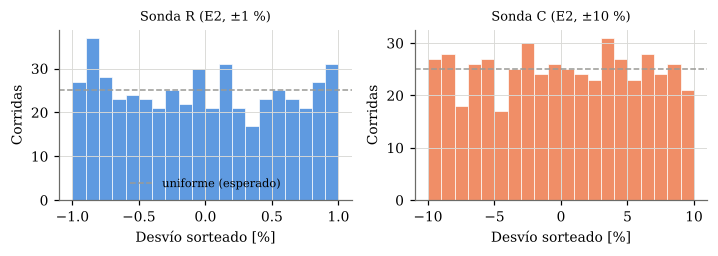

In [10]:
if DISP:
    fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.4))
    esc = 'E2' if 'E2' in DISP else DISP[0]
    for ax, k, t, col in [(axs[0], 'uR', ESC.loc[esc, 'tolR'], AZUL), (axs[1], 'uC', ESC.loc[esc, 'tolC'], NARANJA)]:
        v = 100 * (LT[esc][k] - 1)
        ax.hist(v, bins=20, range=(-100 * t, 100 * t), color=col, alpha=0.75, edgecolor='white', linewidth=0.6)
        ax.axhline(len(v) / 20, color=GRIS, ls='--', lw=1, label='uniforme (esperado)')
        ax.set(xlabel='Desvío sorteado [%]', ylabel='Corridas', title=f'Sonda {"R" if k == "uR" else "C"} ({esc}, ±{100*t:g} %)')
        ax.title.set_fontsize(8.5)
    axs[0].legend(fontsize=7.5, loc='lower center')
    fig.tight_layout(); guardar(fig, 'fig_mc_muestreo'); plt.show()

### 5.1.1 Diagnóstico del generador con `filtro_mc_sondas.cir`
Se leen los nueve valores sorteados en cada corrida del netlist de diagnóstico, normalizados a $u = (x/x_0 - 1)/t \in [-1, 1]$. Se verifica:
(i) si las sondas `Rpr`/`Rpc` coinciden con las del Monte Carlo E2 (misma secuencia ⇒ los valores son los de cada corrida del filtro);
(ii) que los $u$ de los cuatro escenarios sean idénticos (LTspice usa siempre la misma semilla); (iii) la distribución de cada sorteo (KS) y las
correlaciones entre ellos.

In [11]:
def leer_raw_por_corrida(nombre):
    """Lee un .raw de LTspice con un punto AC por paso de .step (eje = parámetro 'run'). spicelib no admite este caso."""
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            b = p.read_bytes(); clave = 'Binary:\n'.encode('utf-16-le'); i = b.find(clave)
            cab = b[:i].decode('utf-16-le')
            nombres = re.findall(r'^\t\d+\t(\S+)\t', cab.split('Variables:\n', 1)[1], re.M)
            datos = np.frombuffer(b[i + len(clave):], dtype=np.complex128).reshape(-1, len(nombres))
            return pd.DataFrame({n: (np.real(datos[:, k]) if k == 0 else np.abs(datos[:, k])) for k, n in enumerate(nombres)})
    return None

U_LT, DIAG = None, {}
sond = leer_raw_por_corrida('filtro_mc_sondas.raw')
if sond is not None:
    pasos = sond['run'].astype(int).values
    vals = {e: (sond[f'V(p{e.lower()})'].values if e.startswith('R') else sond[f'I(V{e})'].values / (2 * np.pi * 1e3)) for e in ELEM}
    U_LT = pd.DataFrame({e: (vals[e] / NOM[e] - 1) / tol_de(e, 'E2') for e in ELEM}, index=pasos)
    U_LT['pr'] = (sond['V(pr)'].values - 1) / ESC.loc['E2', 'tolR']; U_LT['pc'] = (sond['V(pc)'].values - 1) / ESC.loc['E2', 'tolC']
    if 'E2' in DISP:
        DIAG['dif. máx. sondas vs MC E2'] = max(np.max(np.abs(U_LT['pr'].values - (LT['E2']['uR'].values - 1) / ESC.loc['E2', 'tolR'])),
                                                np.max(np.abs(U_LT['pc'].values - (LT['E2']['uC'].values - 1) / ESC.loc['E2', 'tolC'])))
    if len(DISP) == len(ESC):
        DIAG['dif. máx. de u entre escenarios'] = max(
            np.max(np.abs((LT[e]['uR'] - 1).values / ESC.loc[e, 'tolR'] - (LT['E2']['uR'] - 1).values / ESC.loc['E2', 'tolR'])) for e in DISP)
    DIAG['rango de u'] = (U_LT[ELEM].values.min(), U_LT[ELEM].values.max())
    DIAG['KS p mínimo (uniforme)'] = min(stats.kstest(U_LT[c], stats.uniform(-1, 2).cdf).pvalue for c in U_LT)
    CORR = U_LT.corr()
    off = CORR.where(~np.eye(len(CORR), dtype=bool)).abs()
    DIAG['|r| máximo entre sorteos'] = off.max().max()
    DIAG['par de |r| máximo'] = off.stack().idxmax()
    DIAG['r(C1, C2)'] = CORR.loc['C1', 'C2']
    DIAG['límite 95 % para r (independientes)'] = 1.96 / np.sqrt(len(U_LT))
    DIAG['pares fuera del límite 95 %'] = int((off.stack() > 1.96 / np.sqrt(len(U_LT))).sum() // 2)
    DIAG['pares totales'] = len(U_LT.columns) * (len(U_LT.columns) - 1) // 2
    print(pd.Series(DIAG, dtype=object))
    print(CORR.round(3))
else:
    print('Falta ltspice/resultados/filtro_mc_sondas.raw (correr filtro_mc_sondas.cir en LTspice)')

# Secuencia larga: 5000 corridas del mismo generador
U5 = None
s5 = leer_raw_por_corrida('filtro_mc_sondas_5000.raw')
if s5 is not None:
    U5 = pd.DataFrame({e: ((s5[f'V(p{e.lower()})'].values if e.startswith('R') else s5[f'I(V{e})'].values / (2 * np.pi * 1e3)) / NOM[e] - 1)
                       / tol_de(e, 'E2') for e in ELEM})
    U5['pr'] = (s5['V(pr)'].values - 1) / ESC.loc['E2', 'tolR']; U5['pc'] = (s5['V(pc)'].values - 1) / ESC.loc['E2', 'tolC']
    C5 = U5.corr(); off5 = C5.where(~np.eye(len(C5), dtype=bool)).abs().stack()
    lim5 = 1.96 / np.sqrt(len(U5))
    DIAG['5000: primeras 500 iguales a la muestra'] = bool(U_LT is not None and np.allclose(U5.iloc[:len(U_LT)].values, U_LT.values, atol=1e-9))
    DIAG['5000: r(C1, C2)'] = C5.loc['C1', 'C2']
    DIAG['5000: |r| máximo'] = off5.max(); DIAG['5000: límite 95 %'] = lim5
    DIAG['5000: pares fuera del límite 95 %'] = int((off5 > lim5).sum() // 2)
    DIAG['5000: KS p mínimo'] = min(stats.kstest(U5[c], stats.uniform(-1, 2).cdf).pvalue for c in U5)
    bloques = [U5.iloc[k:k + 500][['C1', 'C2']].corr().iloc[0, 1] for k in range(0, len(U5), 500)]
    DIAG['5000: r(C1, C2) por bloques de 500'] = np.round(bloques, 3)
    print(pd.Series({k: v for k, v in DIAG.items() if k.startswith('5000')}, dtype=object))

dif. máx. sondas vs MC E2                                                    0.0
dif. máx. de u entre escenarios                                              0.0
rango de u                             (-0.9999757156018552, 0.9998831553155996)
KS p mínimo (uniforme)                                                  0.114189
|r| máximo entre sorteos                                                0.163998
par de |r| máximo                                                       (C1, C2)
r(C1, C2)                                                               0.163998
límite 95 % para r (independientes)                                     0.087654
pares fuera del límite 95 %                                                    4
pares totales                                                                 55
dtype: object
       R0a    R0b    R1a    R1b    R2a    R2b     C0     C1     C2     pr  \
R0a  1.000 -0.006 -0.008  0.005 -0.042  0.034  0.042  0.055  0.059 -0.041   
R0b -0.006  1.000  0.0

### 5.2 Familia de respuestas y extracción de $f_r$, $f_0$ y $Q$ de cada corrida
Del `.raw` se leen las 500 respuestas de cada escenario. Para obtener la distribución de los parámetros del circuito a partir de la simulación
(y no de las fórmulas) se ajusta a cada curva el modelo $H(s) = \frac{\omega_r}{s+\omega_r}\cdot\frac{\omega_0^2}{s^2+(\omega_0/Q)s+\omega_0^2}$
por mínimos cuadrados sobre la ganancia en dB entre 10 Hz y 10 kHz, igual que con la medición (notebook 04).

In [12]:
def leer_raw_mc(esc):
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / f'filtro_TL072_mc_{esc}.raw'
        if p.exists():
            raw = RawRead(str(p))
            pasos = raw.get_steps()
            fr_ = np.abs(raw.get_trace('frequency').get_wave(pasos[0]))
            V = np.array([raw.get_trace('V(6)').get_wave(k) for k in pasos])
            return fr_, V
    return None

def H_mod(f, fr, f0, Q):
    sj = 2j * np.pi * f; wr, w0 = 2 * np.pi * fr, 2 * np.pi * f0
    return wr / (sj + wr) * w0**2 / (sj**2 + w0 / Q * sj + w0**2)

def ajustar(f, v):
    m = (f >= 10) & (f <= 1e4); g = 20 * np.log10(np.abs(v[m]))
    p0 = [NOMINAL['fr'], NOMINAL['f0'], NOMINAL['Q']]
    r = optimize.least_squares(lambda p: 20 * np.log10(np.abs(H_mod(f[m], *p))) - g, p0, x_scale=[100, 100, 0.1])
    return r.x, np.sqrt(np.mean(r.fun**2))

RAW = {esc: leer_raw_mc(esc) for esc in DISP}
for esc in DISP:
    if RAW[esc] is None:
        continue
    f_, V = RAW[esc]
    aj = np.array([ajustar(f_, v)[0] for v in V]); rms = np.array([ajustar(f_, v)[1] for v in V[:20]])
    LT[esc]['fr'], LT[esc]['f0'], LT[esc]['Q'] = aj[:, 0], aj[:, 1], aj[:, 2]
    print(f'{esc}: {len(V)} curvas; residuo rms típico del ajuste = {np.median(rms):.4f} dB')

E1: 500 curvas; residuo rms típico del ajuste = 0.0012 dB


E2: 500 curvas; residuo rms típico del ajuste = 0.0012 dB


E3: 500 curvas; residuo rms típico del ajuste = 0.0012 dB


E4: 500 curvas; residuo rms típico del ajuste = 0.0013 dB


Prototipo: {'Ap': 0.590833, 'A4k': 35.2153, 'f3dB': 1278.84, 'fr': 784.5081494420183, 'f0': 1241.04, 'Q': 1.43435, 'G1k': 0.6}


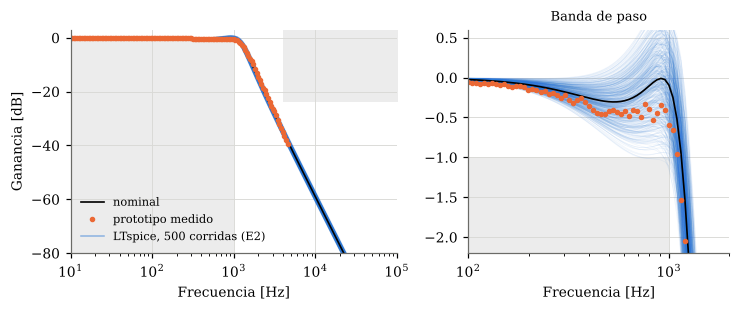

In [13]:
# Prototipo medido (notebook 04): punto de comparación
def macros_tex(p):
    if not p.exists():
        return {}
    return {m.group(1): float(m.group(2)) for m in re.finditer(r'\\newcommand\{\\(\w+)\}\{([-\d.eE+]+)\}', p.read_text(encoding='utf-8'))}
M04 = macros_tex(RES / 'valores_nb04.tex')
PROTO = {}
if M04:
    fr_nom_sinRs = 1 / (2 * np.pi * (NOM['R0a'] + NOM['R0b']) * NOM['C0'])
    PROTO = {'Ap': M04['mApMaxMed'], 'A4k': M04['mAcuatrokMed'], 'f3dB': M04['mFtresdBMed'],
             'fr': NOMINAL['fr'] * M04['mFrAj'] / fr_nom_sinRs,      # desvío relativo del ajuste, referido al nominal con Rs
             'f0': M04['mFoAj'], 'Q': M04['mQAj'], 'G1k': -M04['mGunokMed']}
print('Prototipo:', PROTO)

if DISP and RAW.get('E2' if 'E2' in DISP else DISP[0]) is not None:
    esc = 'E2' if 'E2' in DISP else DISP[0]
    f_, V = RAW[esc]
    fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.9), gridspec_kw={'width_ratios': [1.25, 1]})
    for ax, (xl, yl) in zip(axs, [((10, 1e5), (-80, 3)), ((100, 2000), (-2.2, 0.6))]):
        for v in V:
            ax.semilogx(f_, 20 * np.log10(np.abs(v)), color=AZUL, lw=0.4, alpha=0.08)
        ax.semilogx(f_, 20 * np.log10(np.abs(H_comp(f_, **comps(NOM)))), color='k', lw=1.1, label='nominal')
        if (RES / 'mediciones_procesadas.csv').exists():
            md = pd.read_csv(RES / 'mediciones_procesadas.csv'); md = md[md['valido']]
            ax.semilogx(md['frecuencia_Hz'], md['ganancia_dB'], 'o', ms=2.6, color=NARANJA, label='prototipo medido')
        ax.fill_between([xl[0], FP], -AP, -100, color=GRIS, alpha=0.18, lw=0)
        ax.fill_between([FS, 1e6], -AS, 10, color=GRIS, alpha=0.18, lw=0)
        ax.set(xlim=xl, ylim=yl, xlabel='Frecuencia [Hz]')
    axs[0].set_ylabel('Ganancia [dB]'); axs[0].plot([], [], color=AZUL, lw=1, alpha=0.5, label=f'LTspice, {len(V)} corridas ({esc})')
    axs[0].legend(fontsize=7.5, loc='lower left'); axs[1].set_title('Banda de paso', fontsize=8.5)
    fig.tight_layout(); guardar(fig, 'fig_mc_curvas'); plt.show()

### 5.2.1 Contraste corrida por corrida (si la secuencia se reproduce)
Con los valores de cada corrida se evalúa la transferencia exacta (AO ideal) y se compara con lo que midió LTspice (modelo TL072) en esa misma corrida.
Las diferencias deben ser chicas y sistemáticas: efecto del AO real, de la grilla de 50 puntos por década y de la interpolación de `.meas`.

In [14]:
POR_CORRIDA = {}
REPRODUCE = bool(DIAG) and DIAG.get('dif. máx. sondas vs MC E2', 1) < 1e-6
if REPRODUCE:
    for e in DISP:
        x = {el: NOM[el] * (1 + tol_de(el, e) * U_LT[el].values) for el in ELEM}
        py = evaluar(x)
        dif = {k: LT[e][k].values - py[k] for k in ('Ap', 'G1k', 'G4k', 'f3dB', 'fr', 'f0', 'Q') if k in LT[e]}
        POR_CORRIDA[e] = {'py': py, 'dif': dif}
        LT[e]['cumple_py'] = cumple(py)
    filas = []
    for e in DISP:
        dif = POR_CORRIDA[e]['dif']
        fila = {'escenario': e}
        for k, v in dif.items():
            rel = k in ('f3dB', 'fr', 'f0', 'Q')
            v_ = 100 * v / NOMINAL[k] if rel else v
            fila[f'{k} media'] = v_.mean(); fila[f'{k} máx|·|'] = np.abs(v_).max()
        ok_lt = (LT[e]['Ap'] <= AP) & (LT[e]['A4k'] >= AS)
        fila['veredicto distinto'] = int((ok_lt != LT[e]['cumple_py']).sum())
        filas.append(fila)
    TAB_PC = pd.DataFrame(filas).set_index('escenario')
    print('Diferencias LTspice − Python con los mismos componentes (dB o %):')
    print(TAB_PC.round(4).T)
    # Correlación muestral de C1 y C2 y su efecto sobre σ(f0) y σ(Q)
    print(f"r(C1, C2) en la muestra = {CORR.loc['C1','C2']:.3f}")
elif DIAG:
    print('Las sondas NO coinciden con las del Monte Carlo: no se puede reconstruir cada corrida; se informa solo el diagnóstico estadístico.')

Diferencias LTspice − Python con los mismos componentes (dB o %):
escenario               E1      E2      E3      E4
Ap media            0.0012  0.0011  0.0017  0.0020
Ap máx|·|           0.0064  0.0065  0.0059  0.0057
G1k media          -0.0046 -0.0046 -0.0047 -0.0047
G1k máx|·|          0.0069  0.0066  0.0057  0.0052
G4k media           0.0043  0.0043  0.0042  0.0042
G4k máx|·|          0.0064  0.0059  0.0051  0.0046
f3dB media         -0.1139 -0.1164 -0.1122 -0.1246
f3dB máx|·|         0.2529  0.2363  0.1836  0.1697
fr media           -0.0589 -0.0587 -0.0586 -0.0586
fr máx|·|           0.0795  0.0760  0.0671  0.0623
f0 media           -0.0630 -0.0629 -0.0626 -0.0625
f0 máx|·|           0.0845  0.0805  0.0712  0.0663
Q media             0.0939  0.0940  0.0940  0.0941
Q máx|·|            0.1135  0.1112  0.1022  0.0977
veredicto distinto  1.0000  0.0000  0.0000  0.0000
r(C1, C2) en la muestra = 0.164


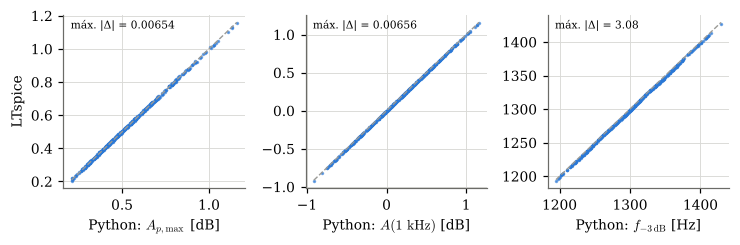

In [15]:
if POR_CORRIDA.get('E2'):
    d2, pc = LT['E2'], POR_CORRIDA['E2']
    fig, axs = plt.subplots(1, 3, figsize=(6.8, 2.3))
    for ax, k, et, rel in [(axs[0], 'Ap', r'$A_{p,\max}$ [dB]', False), (axs[1], 'G1k', r'$A(1\ \mathrm{kHz})$ [dB]', False),
                           (axs[2], 'f3dB', r'$f_{-3\,\mathrm{dB}}$ [Hz]', False)]:
        ax.plot(pc['py'][k], d2[k], '.', ms=2.5, color=AZUL, alpha=0.6)
        lo, hi = np.min(pc['py'][k]), np.max(pc['py'][k]); ax.plot([lo, hi], [lo, hi], color=GRIS, lw=0.9, ls='--')
        ax.set(xlabel=f'Python: {et}', ylabel='LTspice' if ax is axs[0] else None)
        ax.text(0.04, 0.92, f'máx. |Δ| = {np.abs(pc["dif"][k]).max():.3g}', transform=ax.transAxes, fontsize=7)
    fig.tight_layout(); guardar(fig, 'fig_mc_por_corrida'); plt.show()

### 5.3 Distribuciones, rendimiento y contraste con Python y con la predicción lineal
Para cada escenario: rendimiento con intervalo de confianza del 95 % (Wilson) para LTspice, contra el Monte Carlo de Python y el linealizado; prueba
de Kolmogorov–Smirnov de dos muestras entre LTspice y Python para cada parámetro.

In [16]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; w = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return 100 * p, max(0.0, 100 * (c - w)), min(100.0, 100 * (c + w))

RESUMEN = []
for esc in ESC.index:
    r, rl = PY[esc], LIN[esc]
    fila = {'escenario': esc, 'tolR': ESC.loc[esc, 'tolR'], 'tolC': ESC.loc[esc, 'tolC'],
            'rend_py': 100 * cumple(r).mean(), 'rend_lin': 100 * np.mean((rl['Ap'] <= AP) & (rl['A4k'] >= AS)),
            'Ap95_py': np.percentile(r['Ap'], 95), 'Ap95_lin': np.percentile(rl['Ap'], 95)}
    if esc in DISP:
        d = LT[esc]; ok = (d['Ap'] <= AP) & (d['A4k'] >= AS)
        fila['rend_lt'], fila['rend_lt_inf'], fila['rend_lt_sup'] = wilson(int(ok.sum()), len(d))
        fila['Ap95_lt'] = np.percentile(d['Ap'], 95)
        fila['A4min_lt'] = d['A4k'].min(); fila['Asbmin_lt'] = d['Asb'].min()
        for k in ('Ap', 'G1k', 'G4k', 'f3dB', 'fr', 'f0', 'Q'):
            if k in d:
                fila[f'KS_{k}'] = stats.ks_2samp(d[k], r[k]).pvalue
    RESUMEN.append(fila)
RESUMEN = pd.DataFrame(RESUMEN).set_index('escenario')
RESUMEN.round(3)

,tolR,tolC,rend_py,rend_lin,Ap95_py,Ap95_lin,rend_lt,rend_lt_inf,rend_lt_sup,Ap95_lt,A4min_lt,Asbmin_lt,KS_Ap,KS_G1k,KS_G4k,KS_f3dB,KS_fr,KS_f0,KS_Q
escenario,,,,,,,,,,,,,,,,,,,
E1,0.05,0.10,96.354,96.485,0.958,0.954,96.0,93.903,97.396,0.957,31.953,31.953,0.846,0.500,0.734,0.447,0.332,0.420,0.106
E2,0.01,0.10,98.281,98.449,0.894,0.895,97.8,96.104,98.767,0.880,32.170,32.170,0.636,0.437,0.553,0.598,0.193,0.209,0.271
E3,0.01,0.05,100.000,100.000,0.547,0.548,100.0,99.238,100.000,0.548,33.487,33.487,0.458,0.647,0.638,0.158,0.083,0.286,0.374
E4,0.01,0.02,100.000,100.000,0.394,0.394,100.0,99.238,100.000,0.392,34.184,34.184,0.564,0.938,0.614,0.001,0.135,0.136,0.043


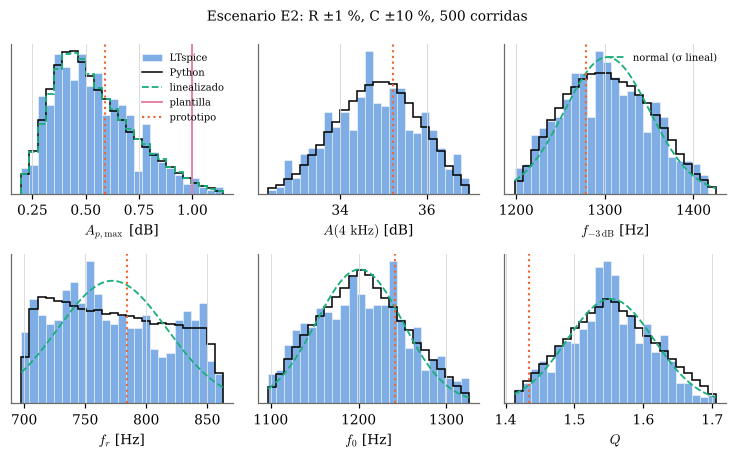

In [17]:
PARAMS = [('Ap', r'$A_{p,\max}$ [dB]', 1, AP), ('A4k', r'$A(4\ \mathrm{kHz})$ [dB]', 1, AS), ('f3dB', r'$f_{-3\,\mathrm{dB}}$ [Hz]', 1, None),
          ('fr', r'$f_r$ [Hz]', 1, None), ('f0', r'$f_0$ [Hz]', 1, None), ('Q', r'$Q$', 1, None)]
if DISP:
    esc = 'E2' if 'E2' in DISP else DISP[0]
    d, r = LT[esc], PY[esc]
    fig, axs = plt.subplots(2, 3, figsize=(6.8, 4.2))
    for ax, (k, et, _, lim) in zip(axs.flat, PARAMS):
        if k not in d:
            ax.axis('off'); continue
        lo, hi = np.percentile(np.r_[r[k], d[k]], [0.2, 99.8])
        bins = np.linspace(lo, hi, 26)
        ax.hist(d[k], bins=bins, density=True, color=AZUL, alpha=0.6, edgecolor='white', linewidth=0.5, label='LTspice')
        hpy, _ = np.histogram(r[k], bins=bins, density=True)
        ax.stairs(hpy, bins, color='k', lw=1.0, label='Python')
        if k not in ('Ap', 'A4k'):   # aproximación normal con la σ lineal (σ relativa × nominal)
            sg = sigma_lineal(esc, k) * NOMINAL[k]
            xx = np.linspace(lo, hi, 200); ax.plot(xx, stats.norm.pdf(xx, NOMINAL[k], sg), color=VERDE, ls='--', lw=1.2, label='normal (σ lineal)')
        if k == 'Ap':
            hl, _ = np.histogram(LIN[esc]['Ap'], bins=bins, density=True)
            ax.stairs(hl, bins, color=VERDE, ls='--', lw=1.2, label='linealizado')
        if lim is not None and lo <= lim <= hi:
            ax.axvline(lim, color=MAGENTA, lw=1.2, label='plantilla')
        if k in PROTO and lo <= PROTO[k] <= hi * 1.02:
            ax.axvline(PROTO[k], color=NARANJA, lw=1.4, ls=':', label='prototipo')
        ax.set_xlabel(et); ax.set_yticks([]); ax.grid(axis='y', visible=False)
    axs[0, 0].legend(fontsize=6.5, loc='upper right')
    hh = [h_ for h_ in axs[0, 2].get_lines() if h_.get_label() == 'normal (σ lineal)']
    axs[0, 2].legend(hh, [h_.get_label() for h_ in hh], fontsize=6.5, loc='upper right', handlelength=1.8)
    fig.suptitle(f'Escenario {esc}: R ±{100*ESC.loc[esc,"tolR"]:g} %, C ±{100*ESC.loc[esc,"tolC"]:g} %, {len(d)} corridas', fontsize=9)
    fig.tight_layout(); guardar(fig, 'fig_mc_histogramas'); plt.show()

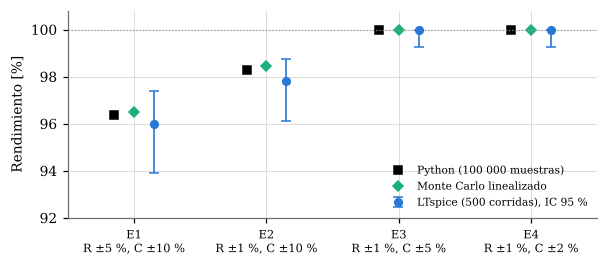

In [18]:
if DISP:
    fig, ax = plt.subplots(figsize=(5.6, 2.5))
    x = np.arange(len(ESC))
    ax.plot(x - 0.15, RESUMEN['rend_py'], 's', color='k', ms=5, label='Python (100 000 muestras)')
    ax.plot(x, RESUMEN['rend_lin'], 'D', color=VERDE, ms=4.5, label='Monte Carlo linealizado')
    if 'rend_lt' in RESUMEN:
        y = RESUMEN['rend_lt'].values
        err = np.clip(np.vstack([y - RESUMEN['rend_lt_inf'].values, RESUMEN['rend_lt_sup'].values - y]), 0, None)
        ax.errorbar(x + 0.15, y, yerr=err, fmt='o', color=AZUL, ms=5, capsize=3, lw=1.1, label=f'LTspice ({N_RUN} corridas), IC 95 %')
    ax.axhline(100, color=GRIS, lw=0.8, ls=':')
    ax.set_xticks(x, [f'{e}\nR ±{100*ESC.loc[e,"tolR"]:g} %, C ±{100*ESC.loc[e,"tolC"]:g} %' for e in ESC.index], fontsize=7.5)
    ax.set(ylabel='Rendimiento [%]', ylim=(92, 100.8), xlim=(-0.5, len(ESC) - 0.5)); ax.legend(fontsize=7, loc='lower right')
    fig.tight_layout(); guardar(fig, 'fig_mc_rendimiento'); plt.show()

### 5.4 Ubicación del prototipo en la distribución
Se calcula qué fracción de los circuitos simulados del escenario E2 (el del prototipo) tiene un valor más extremo que el medido.

In [19]:
UBIC = {}
if PROTO and 'E2' in PY:
    for k in ('Ap', 'fr', 'f0', 'Q', 'f3dB'):
        ref = LT['E2'][k] if ('E2' in DISP and k in LT['E2']) else PY['E2'][k]
        UBIC[k] = 100 * np.mean(ref >= PROTO[k]) if PROTO[k] >= np.median(ref) else 100 * np.mean(ref <= PROTO[k])
    print({k: f'{v:.1f} % de los circuitos es más extremo' for k, v in UBIC.items()})

{'Ap': '35.0 % de los circuitos es más extremo', 'fr': '38.8 % de los circuitos es más extremo', 'f0': '25.4 % de los circuitos es más extremo', 'Q': '2.4 % de los circuitos es más extremo', 'f3dB': '36.2 % de los circuitos es más extremo'}


## 6. Exportación para el informe

In [20]:
def guardar_tab(nombre, cuerpo, cab, formato):
    t = [rf'\begin{{tabular}}{{@{{}}{formato}@{{}}}}', r'\toprule', cab + r' \\', r'\midrule'] + [f + r' \\' for f in cuerpo] + [r'\bottomrule', r'\end{tabular}']
    (RES / f'{nombre}.tex').write_text('\n'.join(t) + '\n', encoding='utf-8')

guardar_tab('tab_mc_escenarios',
            [f'{e} & $\\pm{num(100*ESC.loc[e,"tolR"],0)}$ & $\\pm{num(100*ESC.loc[e,"tolC"],0)}$ & {N_RUN} & {ESC.loc[e,"motivo"].replace("%", chr(92)+"%")}'
             for e in ESC.index],
            r'Escenario & $t_R$ [\%] & $t_C$ [\%] & Corridas & Motivo', 'lcccl')

filas = []
for e in ESC.index:
    rr = RESUMEN.loc[e]
    lt = (f'{num(rr["rend_lt"],1)} [{num(rr["rend_lt_inf"],1)}; {num(rr["rend_lt_sup"],1)}]' if 'rend_lt' in rr and not np.isnan(rr.get('rend_lt', np.nan)) else '---')
    ap_lt = num(rr['Ap95_lt'], 3) if 'Ap95_lt' in rr and not np.isnan(rr.get('Ap95_lt', np.nan)) else '---'
    filas.append(f'{e} & {lt} & {num(rr["rend_py"],1)} & {num(rr["rend_lin"],1)} & {ap_lt} & {num(rr["Ap95_py"],3)} & {num(rr["Ap95_lin"],3)}')
guardar_tab('tab_mc_rendimiento', filas,
            r'& \multicolumn{3}{c}{Rendimiento [\%]} & \multicolumn{3}{c}{$A_{p,\max}$, percentil 95 [dB]} \\ \cmidrule(lr){2-4}\cmidrule(l){5-7}'
            r' Escenario & LTspice [IC 95\,\%] & Python & Linealizado & LTspice & Python & Linealizado', 'lcccccc')

ETQ = {'G1k': (r'$A(\qty{1}{\kilo\hertz})$ [dB]', False), 'G4k': (r'$A(\qty{4}{\kilo\hertz})$ [dB]', False),
       'f3dB': (r'$f_{-3\,\text{dB}}$ [\%]', True), 'fr': (r'$f_r$ [\%]', True), 'f0': (r'$f_0$ [\%]', True), 'Q': (r'$Q$ [\%]', True)}
for e in ESC.index:
    filas = []
    for k, (et, rel) in ETQ.items():
        fac = 100 / NOMINAL[k] if rel else 1.0
        lin = sigma_lineal(e, k) * (100 if rel else 1)
        py = PY[e][k].std() * fac
        mism = num(POR_CORRIDA[e]['py'][k].std() * fac, 3) if e in POR_CORRIDA else '---'
        lt = num(LT[e][k].std() * fac, 3) if (e in DISP and k in LT[e]) else '---'
        filas.append(f'{et} & {num(lin,3)} & {num(py,3)} & {mism} & {lt}')
    guardar_tab(f'tab_mc_dispersion_{e}', filas,
                r'& & \multicolumn{2}{c}{$\sigma$ Python} & \\ \cmidrule(lr){3-4} Parámetro & $\sigma$ lineal & \num{100000} muestras & '
                r'mismas \num{500} muestras & $\sigma$ LTspice', 'lcccc')

V = {'NRun': N_RUN, 'MPy': M_PY, 'ErrNet': f'{ERR_NET:.0e}'}
for e in ESC.index:
    E = {'E1': 'Uno', 'E2': 'Dos', 'E3': 'Tres', 'E4': 'Cuatro'}[e]
    rr = RESUMEN.loc[e]
    V[f'RendPy{E}'] = round(rr['rend_py'], 1); V[f'RendLin{E}'] = round(rr['rend_lin'], 1)
    V[f'ApNoventaPy{E}'] = round(rr['Ap95_py'], 3)
    V[f'SigAunokLin{E}'] = round(sigma_lineal(e, 'G1k'), 3); V[f'SigAunokPy{E}'] = round(PY[e]['G1k'].std(), 3)
    if e in DISP:
        V[f'RendLt{E}'] = round(rr['rend_lt'], 1); V[f'RendLtInf{E}'] = round(rr['rend_lt_inf'], 1); V[f'RendLtSup{E}'] = round(rr['rend_lt_sup'], 1)
        V[f'ApNoventaLt{E}'] = round(rr['Ap95_lt'], 3); V[f'AcuatroMinLt{E}'] = round(rr['A4min_lt'], 1)
        V[f'AsbMinLt{E}'] = round(rr['Asbmin_lt'], 1)
        V[f'SigAunokLt{E}'] = round(LT[e]['G1k'].std(), 3)
        ks = [rr[c] for c in RESUMEN.columns if c.startswith('KS_') and not np.isnan(rr[c])]
        V[f'KSmin{E}'] = round(min(ks), 2) if ks else 'nan'
for k, v in UBIC.items():
    V[f'Ubic{ {"Ap": "Ap", "fr": "Fr", "f0": "Fo", "Q": "Q", "f3dB": "Ftres"}[k] }'.replace(' ', '')] = round(v, 1)
if VERIF:
    V['VerifDistintasMin'] = min(v['resultados distintos (G1k)'] for v in VERIF.values())
    V['KSsondaMin'] = round(min(min(v['KS p (uR uniforme)'], v['KS p (uC uniforme)']) for v in VERIF.values()), 2)
V['LTDisponibles'] = len(DISP)
V['Reproduce'] = int(REPRODUCE)
if DIAG:
    V['RCunoCdos'] = round(DIAG['r(C1, C2)'], 3); V['RMax'] = round(DIAG['|r| máximo entre sorteos'], 3)
    V['RLimite'] = round(DIAG['límite 95 % para r (independientes)'], 3)
    V['ParesFuera'] = DIAG['pares fuera del límite 95 %']; V['ParesTot'] = DIAG['pares totales']
    V['KSsondasDiag'] = round(DIAG['KS p mínimo (uniforme)'], 2)
    if '5000: r(C1, C2)' in DIAG:
        V['RCunoCdosLargo'] = round(DIAG['5000: r(C1, C2)'], 3); V['RMaxLargo'] = round(DIAG['5000: |r| máximo'], 3)
        V['RLimiteLargo'] = round(DIAG['5000: límite 95 %'], 3); V['ParesFueraLargo'] = DIAG['5000: pares fuera del límite 95 %']
        V['KSLargo'] = round(DIAG['5000: KS p mínimo'], 2)
        bl = DIAG['5000: r(C1, C2) por bloques de 500']
        V['RBloqMin'] = round(min(bl[1:]), 3); V['RBloqMax'] = round(max(bl[1:]), 3); V['RBloqUno'] = round(bl[0], 3)
        V['PrimerasIguales'] = int(DIAG['5000: primeras 500 iguales a la muestra'])
if REPRODUCE:
    for k_ in ('Ap', 'G1k', 'f3dB', 'f0', 'Q', 'fr'):
        V[f'PcMax{ {"Ap": "Ap", "G1k": "Gunok", "f3dB": "Ftres", "f0": "Fo", "Q": "Q", "fr": "Fr"}[k_] }'.replace(' ', '')] = \
            f"{max(TAB_PC[f'{k_} máx|·|']):.2g}"
        V[f'PcMed{ {"Ap": "Ap", "G1k": "Gunok", "f3dB": "Ftres", "f0": "Fo", "Q": "Q", "fr": "Fr"}[k_] }'.replace(' ', '')] = \
            f"{TAB_PC[f'{k_} media'].mean():.2g}"
    V['PcVeredictos'] = int(TAB_PC['veredicto distinto'].sum())
with open(RES / 'valores_nb05.tex', 'w', encoding='utf-8') as fh:
    fh.write('% Generado automáticamente por notebooks/05_Monte_Carlo_Nivel_II.ipynb — no editar a mano\n')
    for k, v in V.items():
        fh.write(f'\\newcommand{{\\n{k}}}{{{v}}}\n')
print(open(RES / 'valores_nb05.tex', encoding='utf-8').read())

% Generado automáticamente por notebooks/05_Monte_Carlo_Nivel_II.ipynb — no editar a mano
\newcommand{\nNRun}{500}
\newcommand{\nMPy}{100000}
\newcommand{\nErrNet}{2e-14}
\newcommand{\nRendPyUno}{96.4}
\newcommand{\nRendLinUno}{96.5}
\newcommand{\nApNoventaPyUno}{0.958}
\newcommand{\nSigAunokLinUno}{0.462}
\newcommand{\nSigAunokPyUno}{0.461}
\newcommand{\nRendLtUno}{96.0}
\newcommand{\nRendLtInfUno}{93.9}
\newcommand{\nRendLtSupUno}{97.4}
\newcommand{\nApNoventaLtUno}{0.957}
\newcommand{\nAcuatroMinLtUno}{32.0}
\newcommand{\nAsbMinLtUno}{32.0}
\newcommand{\nSigAunokLtUno}{0.458}
\newcommand{\nKSminUno}{0.11}
\newcommand{\nRendPyDos}{98.3}
\newcommand{\nRendLinDos}{98.4}
\newcommand{\nApNoventaPyDos}{0.894}
\newcommand{\nSigAunokLinDos}{0.433}
\newcommand{\nSigAunokPyDos}{0.431}
\newcommand{\nRendLtDos}{97.8}
\newcommand{\nRendLtInfDos}{96.1}
\newcommand{\nRendLtSupDos}{98.8}
\newcommand{\nApNoventaLtDos}{0.88}
\newcommand{\nAcuatroMinLtDos}{32.2}
\newcommand{\nAsbMinLtDos}{32.2}
\newco